# Features Notebook

In [2]:

import pandas as pd
from pathlib import Path
import sys
import matplotlib.pyplot as plt
%pip install openpyxl

# Add src directory to path
sys.path.append('../src')

from utils import load_tennis_data  # noqa: E402

# Try relative path inside repo
data_dir = Path('../data/processed')
rel_path = data_dir / 'match_core.xlsx'
print("Working dir:", Path.cwd())

if rel_path.exists():
    df = pd.read_excel(rel_path)
    print(f"Loaded {len(df)} rows from {rel_path}")
else:
    # Search for matching files in data/processed
    candidates = list(Path("data/processed").glob("match_core.*")) if Path("data/processed").exists() else []
    if candidates:
        chosen = candidates[0]
        print(f"Found file {chosen}, loading...")
        if chosen.suffix.lower() in [".xlsx", ".xls"]:
            df = pd.read_excel(chosen)
        else:
            df = pd.read_csv(chosen)
        print(f"Loaded {len(df)} rows from {chosen}")
    else:
        # Optional: use helper from src/utils.py which handles CSV loading
        try:
            csv_fallback = Path("data/processed/match_core.csv")
            if csv_fallback.exists():
                df = load_tennis_data(str(csv_fallback))
            else:
                raise FileNotFoundError(f"No match_core file found under data/processed. Checked: {rel_path}")
        except Exception as e:
            raise FileNotFoundError(f"Could not locate match_core file: {e}")


# Print the first few rows of the dataframe
print(df.head())

df = df.sort_values(by='Date', ascending=True)

print(df.head())

print(df.columns)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.
Working dir: /workspaces/tennis_betting_efficiency/notebooks
Loaded 24864 rows from ../data/processed/match_core.xlsx
   ATP Location   Tournament       Date       Series   Court Surface  \
0   65    Turin  Masters Cup 2024-11-17  Masters Cup  Indoor    Hard   
1   65    Turin  Masters Cup 2024-11-16  Masters Cup  Indoor    Hard   
2   65    Turin  Masters Cup 2024-11-16  Masters Cup  Indoor    Hard   
3   65    Turin  Masters Cup 2024-11-15  Masters Cup  Indoor    Hard   
4   65    Turin  Masters Cup 2024-11-15  Masters Cup  Indoor    Hard   

         Round  Best of     Winner  ...   PS_L_ip  PS_overround  PS_W_fair  \
0    The Final      3.0  Sinner J.  ...  0.190840      1.045541   0.817473   
1   Semifinals      3.0   Fritz T.  ...  0.675676      1.026553   0.341801   
2   Semifinals      3.0  Sinner J.  ...  0.080128      1.023524   0.921713  

In [3]:
# Add src directory to path
sys.path.append('../src')

from elo_features import compute_elo_rankings

elo_df = compute_elo_rankings(df)
df = pd.merge(df, elo_df, left_index=True, right_index=True)

print(df.describe())

print(df[['elo_winner','elo_loser','proba_elo']].describe())

Elo rankings computing...
5000 matches computed...
10000 matches computed...
15000 matches computed...
20000 matches computed...
                ATP                           Date       Best of  \
count  24864.000000                          24864  24849.000000   
mean      32.243806  2019-11-29 06:02:43.320463360      3.397682   
min        1.000000            2015-01-05 00:00:00      3.000000   
25%       18.000000            2017-04-28 00:00:00      3.000000   
50%       32.000000            2019-08-08 00:00:00      3.000000   
75%       49.000000            2022-07-31 00:00:00      3.000000   
max       68.000000            2024-11-17 00:00:00      5.000000   
std       18.184071                            NaN      0.798272   

              WRank         LRank          WPts          LPts         Wsets  \
count  24853.000000  24810.000000  24854.000000  24810.000000  24710.000000   
mean      59.178650     89.947642   1932.275087   1188.551149      2.163011   
min        1.000000  


Summary statistics for higher_elo_won:
count    24864.000000
mean         0.637146
std          0.480833
min          0.000000
25%          0.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: higher_elo_won, dtype: float64
Proportion of matches where higher-elo player won:
0.6371460746460746


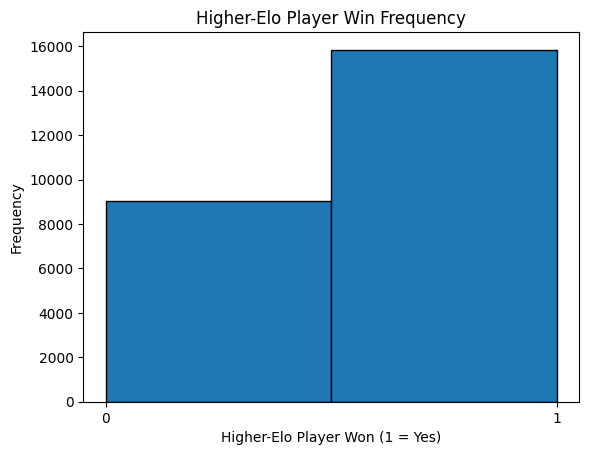


Win rate by surface (higher-elo player):
Surface
Grass    0.656924
Hard     0.636554
Clay     0.630814
Name: higher_elo_won, dtype: float64

Top 15 tournaments where higher-elo players won most often:
Tournament
Adelaide International      0.814815
Tel Aviv Open               0.814815
AEGON International         0.777778
bett1HULKS Indoors          0.777778
bet-at-home Open            0.741935
Hong Kong Tennis Open       0.740741
Singapore Open              0.740741
bett1HULKS Championship     0.740741
Lyon Open                   0.739362
Eastbourne International    0.738806
Vienna Open                 0.733871
Los Cabos Open              0.725000
Topshelf Open               0.722222
Brasil Open                 0.711111
Swiss Indoors               0.705645
Name: higher_elo_won, dtype: float64

Bottom 15 tournaments where higher-elo players won least often:
Tournament
Serbia Open               0.566038
Viking International      0.555556
Srpska Open               0.555556
Apia Internati

In [4]:
# Create a binary variable: 1 if the higher-ranked player (lower rank number) won
df['higher_elo_won'] = (df['elo_winner'] > df['elo_loser']).astype(int)

# Summary statistics
print("\nSummary statistics for higher_elo_won:")
print(df['higher_elo_won'].describe())

# Check overall proportion of matches where higher-elo player won
print("Proportion of matches where higher-elo player won:")
print(df['higher_elo_won'].mean())

# Histogram visualization
plt.hist(df['higher_elo_won'], bins=2, edgecolor='black')
plt.title('Higher-Elo Player Win Frequency')
plt.xlabel('Higher-Elo Player Won (1 = Yes)')
plt.ylabel('Frequency')
plt.xticks([0, 1])
plt.show()

# Analyze by surface
rank_surface_rate = df.groupby('Surface')['higher_elo_won'].mean().sort_values(ascending=False)
print("\nWin rate by surface (higher-elo player):")
print(rank_surface_rate)

# Analyze by tournament
rank_tournament_rate = df.groupby('Tournament')['higher_elo_won'].mean().sort_values(ascending=False)
print("\nTop 15 tournaments where higher-elo players won most often:")
print(rank_tournament_rate.head(15))
print("\nBottom 15 tournaments where higher-elo players won least often:")
print(rank_tournament_rate.tail(15))


In [5]:

# Add src directory to path
sys.path.append('../src')

from utils import load_tennis_data  # noqa: E402

# Try relative path inside repo
data_dir = Path('../data/processed')
rel_path = data_dir / '2024_with_player_stats.csv'
print("Working dir:", Path.cwd())

if rel_path.exists():
    df_2 = pd.read_csv(rel_path)
    print(f"Loaded {len(df)} rows from {rel_path}")
else:
    # Search for matching files in data/processed
    candidates = list(Path("data/processed").glob("match_core.*")) if Path("data/processed").exists() else []
    if candidates:
        chosen = candidates[0]
        print(f"Found file {chosen}, loading...")
        if chosen.suffix.lower() in [".xlsx", ".xls"]:
            df_2 = pd.read_excel(chosen)
        else:
            df_2 = pd.read_csv(chosen)
        print(f"Loaded {len(df)} rows from {chosen}")
    else:
        # Optional: use helper from src/utils.py which handles CSV loading
        try:
            csv_fallback = Path("data/processed/match_core.csv")
            if csv_fallback.exists():
                df_2 = load_tennis_data(str(csv_fallback))
            else:
                raise FileNotFoundError(f"No match_core file found under data/processed. Checked: {rel_path}")
        except Exception as e:
            raise FileNotFoundError(f"Could not locate match_core file: {e}")


# Print the first few rows of the dataframe
print(df_2.head())

print(df_2.notna().sum())

print(df_2.columns)


"""
Add the columns 'Winner_hand', 'Winner_ioc',
       'Winner_player_id', 'Winner_height', 'Winner_age', 'Loser_hand',
       'Loser_ioc', 'Loser_player_id', 'Loser_height', 'Loser_age',
       'Winner_rating', 'Loser_rating' to the features dataset
"""

df_2['Date'] = pd.to_datetime(df_2['Date'])

# Add columns from df_2 to df
df = df.merge(
    df_2[[
        'Date', 'Tournament', 'Winner', 'Loser',
        'Winner_hand', 'Winner_ioc', 'Winner_player_id', 'Winner_height', 'Winner_age',
        'Loser_hand', 'Loser_ioc', 'Loser_player_id', 'Loser_height', 'Loser_age',
        'Winner_rating', 'Loser_rating'
    ]],
    on=['Date', 'Tournament', 'Winner', 'Loser'],
    how='left'
)

print(df.columns)


Working dir: /workspaces/tennis_betting_efficiency/notebooks
Loaded 24864 rows from ../data/processed/2024_with_player_stats.csv
   ATP  Location              Tournament        Date  Series    Court Surface  \
0    1  Brisbane  Brisbane International  2015-01-05  ATP250  Outdoor    Hard   
1    1  Brisbane  Brisbane International  2015-01-05  ATP250  Outdoor    Hard   
2    1  Brisbane  Brisbane International  2015-01-05  ATP250  Outdoor    Hard   
3    1  Brisbane  Brisbane International  2015-01-05  ATP250  Outdoor    Hard   
4    1  Brisbane  Brisbane International  2015-01-06  ATP250  Outdoor    Hard   

       Round  Best of         Winner  ... Winner_player_id  Winner_height  \
0  1st Round      3.0   Duckworth J.  ...         105902.0          183.0   
1  1st Round      3.0  Kokkinakis T.  ...         106423.0          193.0   
2  1st Round      3.0      Chardy J.  ...         104871.0          188.0   
3  1st Round      3.0       Tomic B.  ...         106071.0          196.0   

## H2H

   ATP  Location              Tournament       Date  Series    Court Surface  \
0    1  Brisbane  Brisbane International 2015-01-05  ATP250  Outdoor    Hard   
1    2   Chennai            Chennai Open 2015-01-05  ATP250  Outdoor    Hard   
2    2   Chennai            Chennai Open 2015-01-05  ATP250  Outdoor    Hard   
3    2   Chennai            Chennai Open 2015-01-05  ATP250  Outdoor    Hard   
4    3      Doha  Qatar Exxon Mobil Open 2015-01-05  ATP250  Outdoor    Hard   

       Round  Best of            Winner  ... Loser_hand  Loser_ioc  \
0  1st Round      3.0         Chardy J.  ...          R        KAZ   
1  1st Round      3.0         Muller G.  ...          R        FRA   
2  1st Round      3.0  Haider-Maurer A.  ...          R        ESP   
3  1st Round      3.0          Coric B.  ...          R        NED   
4  1st Round      3.0        Bolelli S.  ...          R        GER   

   Loser_player_id  Loser_height  Loser_age  Winner_rating  Loser_rating  h2h  \
0         104979.

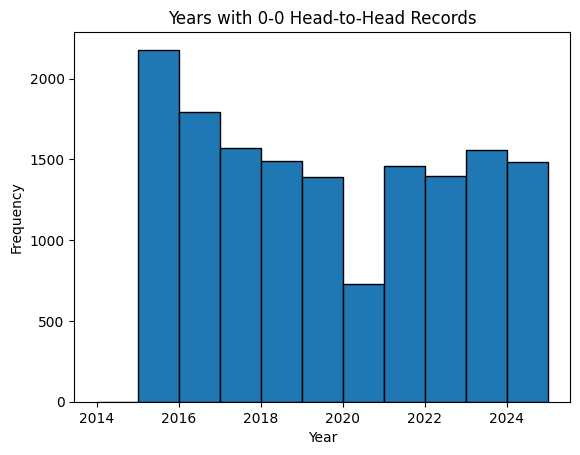

1484


In [6]:
# Add src directory to path
sys.path.append('../src')

from h2h import find_h2h

h2h_record, test_df = find_h2h(df)

print(test_df.head())

print(test_df["Winner"].describe())

print(test_df["h2h"].describe())

# Plot years when h2h is 0-0
plt.hist(test_df[test_df["h2h"] == "0-0"]["Date"].dt.year, bins=range(2014, 2026), edgecolor='black')
plt.title('Years with 0-0 Head-to-Head Records')
plt.xlabel('Year')
plt.ylabel('Frequency')
plt.show()

print(test_df[(test_df["h2h"] == "0-0") & (test_df["Date"].dt.year == 2024)].shape[0])

out_dir = Path("../data/processed")
#test_df.to_excel(out_dir / "h2h_added_matches.xlsx", index=False)

# Merge test_df back to df 
df = df.merge(
    test_df[['Date', 'Tournament', 'Winner', 'Loser', 'h2h','W_h2h', 'L_h2h']],
    on=['Date', 'Tournament', 'Winner', 'Loser'],
    how='left'
)



In [7]:
# Trying to figure out why there are so many 0-0 h2h records

# Count unique unordered player pairs in 2015 and 2024

# Filter rows for 2015 and 2024
unique_pairs = test_df[
    (test_df['Date'].dt.year == 2015) | 
    (test_df['Date'].dt.year == 2024)
][['Winner', 'Loser', 'Date']]

# Extract year
unique_pairs['Year'] = unique_pairs['Date'].dt.year

# Create order-independent pair columns
unique_pairs[['P1', 'P2']] = unique_pairs.apply(
    lambda row: pd.Series(sorted([row['Winner'], row['Loser']])),
    axis=1
)

# Drop duplicates: unique unordered pairs per year
unique_pairs = unique_pairs.drop_duplicates(subset=['P1', 'P2', 'Year'])

# Count unique unordered pairs per year
a = unique_pairs[unique_pairs['Year'] == 2015].shape[0]
b = unique_pairs[unique_pairs['Year'] == 2024].shape[0]

print(f"Unique unordered player pairs in 2015: {a}")
print(f"Unique unordered player pairs in 2024: {b}")

# Count of h2h == "0-0" over the years for unique unordered player pairs
h2h_0_0 = test_df[test_df['h2h'] == "0-0"][['Winner', 'Loser', 'Date']]

# Extract year
h2h_0_0['Year'] = h2h_0_0['Date'].dt.year

# Create order-independent pair columns
h2h_0_0[['P1', 'P2']] = h2h_0_0.apply(
    lambda row: pd.Series(sorted([row['Winner'], row['Loser']])),
    axis=1
)

# Drop duplicates: unique unordered pairs per year
h2h_0_0 = h2h_0_0.drop_duplicates(subset=['P1', 'P2', 'Year'])


# Count unique unordered pairs per year
a = h2h_0_0[h2h_0_0['Year'] == 2015].shape[0]
b = h2h_0_0[h2h_0_0['Year'] == 2024].shape[0]

print(f"Unique unordered player pairs with H2H 0-0 in 2015: {a}")
print(f"Unique unordered player pairs with H2H 0-0 in 2024: {b}")

Unique unordered player pairs in 2015: 2179
Unique unordered player pairs in 2024: 2325
Unique unordered player pairs with H2H 0-0 in 2015: 2179
Unique unordered player pairs with H2H 0-0 in 2024: 1484


In [8]:
print(df.columns)

Index(['ATP', 'Location', 'Tournament', 'Date', 'Series', 'Court', 'Surface',
       'Round', 'Best of', 'Winner', 'Loser', 'WRank', 'LRank', 'WPts', 'LPts',
       'Wsets', 'Lsets', 'B365W', 'B365L', 'PSW', 'PSL', 'B365_W_ip',
       'B365_L_ip', 'B365_overround', 'B365_W_fair', 'B365_L_fair', 'PS_W_ip',
       'PS_L_ip', 'PS_overround', 'PS_W_fair', 'PS_L_fair', 'player1_odds',
       'player2_odds', 'player1_implied_prob', 'player2_implied_prob',
       'overround', 'arb_flag', 'elo_winner', 'elo_loser', 'proba_elo',
       'higher_elo_won', 'Winner_hand', 'Winner_ioc', 'Winner_player_id',
       'Winner_height', 'Winner_age', 'Loser_hand', 'Loser_ioc',
       'Loser_player_id', 'Loser_height', 'Loser_age', 'Winner_rating',
       'Loser_rating', 'h2h', 'W_h2h', 'L_h2h'],
      dtype='object')


## Hand

Loaded 24930 rows
Contingency Table (Winner Hand × Loser Hand):
Loser_hand      L      R  U
Winner_hand                
L             394   2465  1
R            2655  15579  6
U               0      1  0


Conditional Win Probabilities:
--------------------------------------------------
P(R wins | opp is L): 0.5186 (51.86%)
P(L wins | opp is R): 0.4814 (48.14%)
P(R wins | opp is R): 0.5000 (50.00%)
P(L wins | opp is L): 0.5000 (50.00%)


Statistical Significance Test:
--------------------------------------------------
Chi-square statistic: 1.3876
P-value: 0.8464
Degrees of freedom: 4

Result: Handedness matchup is NOT statistically significant (p >= 0.05)

Expected frequencies under independence:
Loser_hand             L             R         U
Winner_hand                                     
L             413.257192   2445.794038  0.948770
R            2635.598313  15598.350789  6.050898
U               0.144496      0.855173  0.000332
Loaded 24930 rows

SURFACE ANALYSIS RESULTS


,Surface,R_wins_vs_L,L_wins_vs_R,Total_mixed_matchups,R_win_rate_vs_L,L_win_rate_vs_R,R_vs_R_matches,L_vs_L_matches,Total_matches
0,Hard,1496,1355,2851,0.524728,0.475272,9245,203,14394
1,Clay,814,794,1608,0.506219,0.493781,4519,142,7657
2,Grass,345,316,661,0.521936,0.478064,1815,49,2879



TOURNAMENT ANALYSIS RESULTS


,Tournament,Surface,R_wins_vs_L,L_wins_vs_R,Total_mixed_matchups,R_win_rate_vs_L,L_win_rate_vs_R,R_vs_R_matches,L_vs_L_matches,Total_matches
0,Australian Open,Hard,142,121,263,0.539924,0.460076,828,15,1270
1,US Open,Hard,140,121,261,0.536398,0.463602,822,14,1270
2,French Open,Clay,125,118,243,0.514403,0.485597,823,19,1270
3,Wimbledon,Grass,135,123,258,0.523256,0.476744,719,15,1143
4,BNP Paribas Open,Hard,97,98,195,0.497436,0.502564,524,17,855
5,Internazionali BNL d'Italia,Clay,64,70,134,0.477612,0.522388,412,9,629
6,Mutua Madrid Open,Clay,62,56,118,0.525424,0.474576,362,6,575
7,Western & Southern Financial Group Masters,Hard,58,41,99,0.585859,0.414141,380,6,550
8,BNP Paribas Masters,Hard,55,53,108,0.509259,0.490741,333,8,510
9,Monte Carlo Masters,Clay,43,37,80,0.537500,0.462500,324,7,495


Loaded 24930 rows
Columns: ['ATP', 'Location', 'Tournament', 'Date', 'Series', 'Court', 'Surface', 'Round', 'Best of', 'Winner', 'Loser', 'WRank', 'LRank', 'WPts', 'LPts', 'W1', 'L1', 'W2', 'L2', 'W3', 'L3', 'W4', 'L4', 'W5', 'L5', 'Wsets', 'Lsets', 'Comment', 'B365W', 'B365L', 'EXW', 'EXL', 'LBW', 'LBL', 'PSW', 'PSL', 'MaxW', 'MaxL', 'AvgW', 'AvgL', 'Winner_hand', 'Winner_ioc', 'Winner_player_id', 'Winner_height', 'Winner_age', 'Loser_hand', 'Loser_ioc', 'Loser_player_id', 'Loser_height', 'Loser_age', 'Winner_rating', 'Loser_rating']
HANDEDNESS ANALYSIS BY SURFACE

Surface Analysis Results:
Surface  R_wins_vs_L  L_wins_vs_R  Total_mixed_matchups  R_win_rate_vs_L  L_win_rate_vs_R  R_vs_R_matches  L_vs_L_matches  Total_matches
   Hard         1496         1355                  2851         0.524728         0.475272            9245             203          14394
   Clay          814          794                  1608         0.506219         0.493781            4519             142      

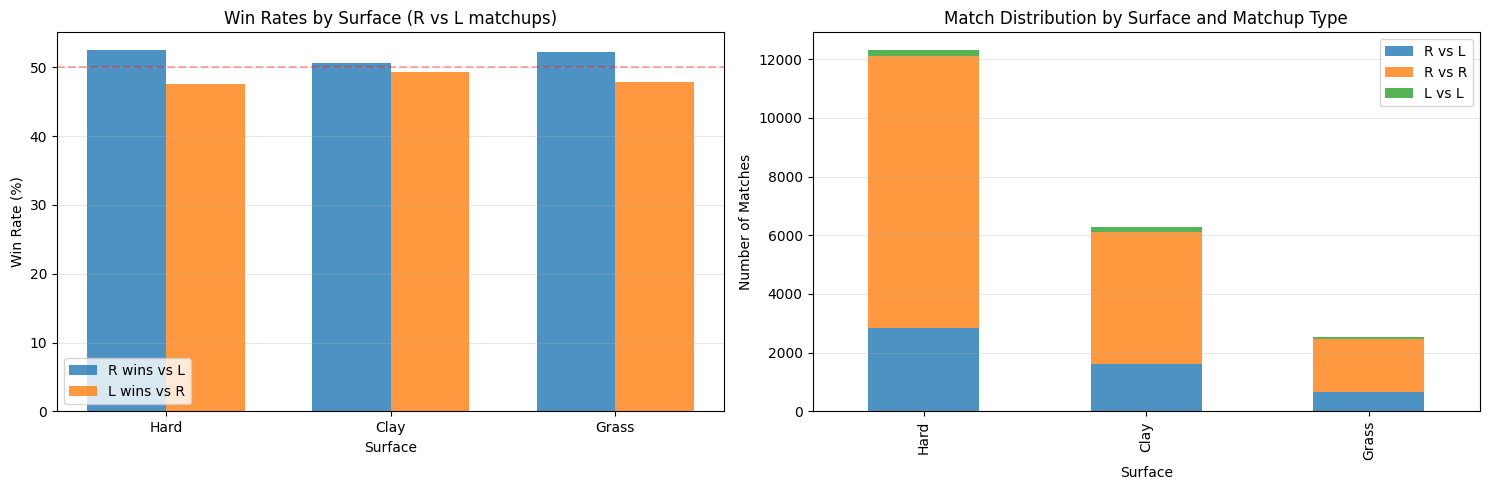

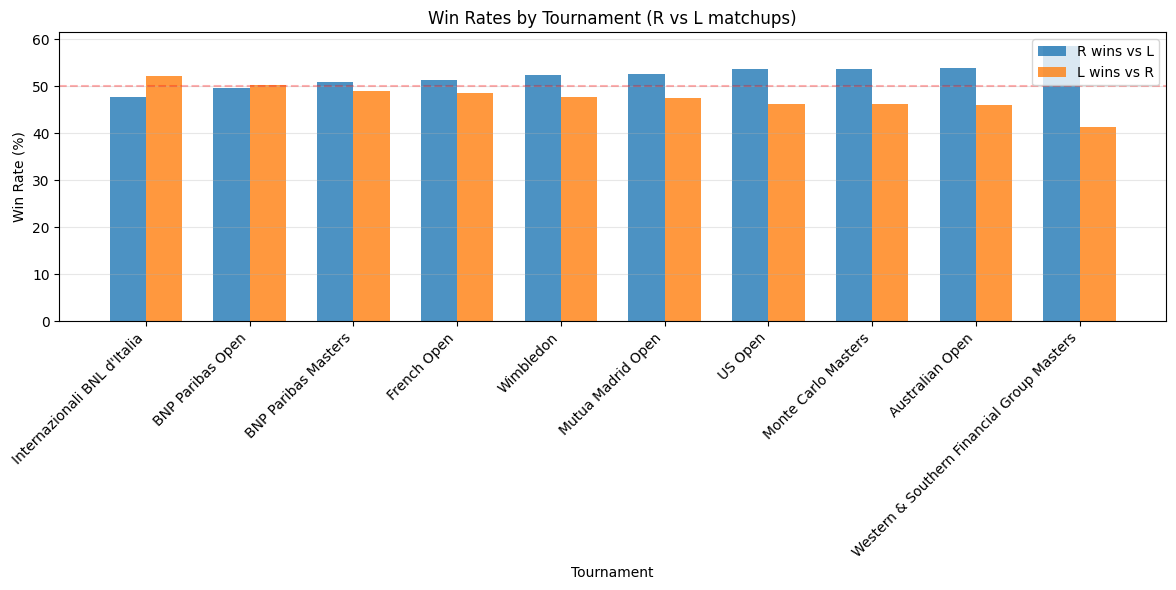

In [9]:
import pandas as pd
import sys
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append('../src') 

from playerstatsfeatures import analyze_handedness_probabilities

data_dir = Path('../data/processed')
rel_path = data_dir / '2024_with_player_stats.csv'

df = pd.read_csv(rel_path)
print(f"Loaded {len(df)} rows")

probabilities, chi2, p_value = analyze_handedness_probabilities(df)

from playerstatsfeatures import analyze_handedness_by_surface

data_dir = Path('../data/processed')
rel_path = data_dir / '2024_with_player_stats.csv'

df = pd.read_csv(rel_path)
print(f"Loaded {len(df)} rows")

surface_results = analyze_handedness_by_surface(df)

print("\n" + "="*70)
print("SURFACE ANALYSIS RESULTS")
print("="*70)
display(surface_results)

from playerstatsfeatures import analyze_handedness_by_tournament

tournament_results = analyze_handedness_by_tournament(df, top_n=10)

print("\n" + "="*70)
print("TOURNAMENT ANALYSIS RESULTS")
print("="*70)
display(tournament_results)

data_dir = Path('../data/processed')
rel_path = data_dir / '2024_with_player_stats.csv'

df = pd.read_csv(rel_path)
print(f"Loaded {len(df)} rows")
print(f"Columns: {df.columns.tolist()}")

from playerstatsfeatures import full_handedness_analysis

surface_results, tournament_results = full_handedness_analysis(df)

## Age and Height Difference


AGE & HEIGHT ANALYSIS
DESCRIPTIVE STATISTICS

Age Difference (Winner - Loser):
  Mean: 0.28 years
  Median: 0.30 years
  Std Dev: 5.99 years
  Min: -20.20 years
  Max: 21.60 years

  Younger player wins: 10016 (40.2%)
  Older player wins: 10899 (43.7%)
  Same age: 186 (0.7%)

Height Difference (Winner - Loser):
  Mean: 0.90 cm
  Median: 0.00 cm
  Std Dev: 9.96 cm
  Min: -41.00 cm
  Max: 41.00 cm

  Shorter player wins: 8701 (34.9%)
  Taller player wins: 10197 (40.9%)
  Same height: 2179 (8.7%)

STATISTICAL SIGNIFICANCE TESTS

Age Difference T-Test (H0: mean difference = 0):
  T-statistic: 6.6773
  P-value: 0.0000
  Significant: Yes (α=0.05)
  → Winners tend to be older than losers

Height Difference T-Test (H0: mean difference = 0):
  T-statistic: 13.0496
  P-value: 0.0000
  Significant: Yes (α=0.05)
  → Winners tend to be taller than losers

Age Category Distribution:
Age_diff
Younger    7411
Similar    5558
Older      8132
Name: count, dtype: int64

WIN RATE ANALYSIS BY DIFFERENCE B

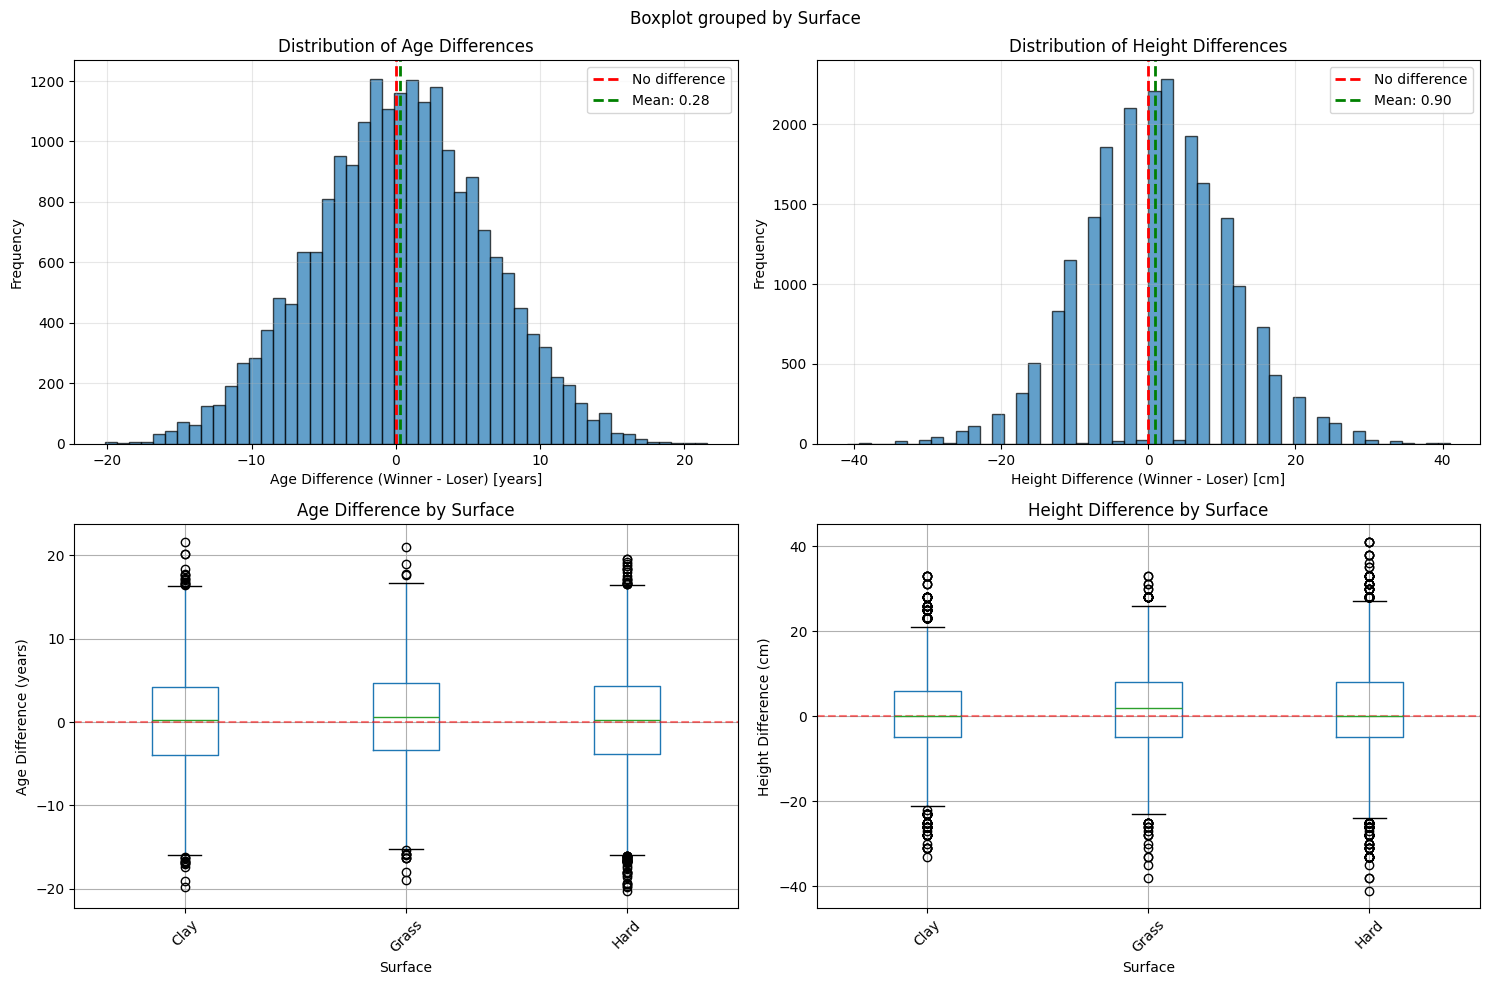

In [10]:
import pandas as pd
from pathlib import Path
import sys
import matplotlib.pyplot as plt

from playerstatsfeatures import (
    full_handedness_analysis,
    analyze_handedness_by_surface, 
    analyze_handedness_by_tournament,
    full_age_height_analysis
)
print("\n" + "="*70)
print("AGE & HEIGHT ANALYSIS")
print("="*70)
df_with_diffs = full_age_height_analysis(df)

## Country (Home vs Away)

In [11]:
import pandas as pd
from pathlib import Path
from IPython.display import display  # Import display

# Import functions
from playerstatsfeatures import (
    full_home_advantage_analysis,
    tournament_country_mapping
)

# Load data
df = pd.read_csv('../data/processed/2024_with_player_stats.csv')

# Run analysis
df_with_home, stats, country_results, surface_results = full_home_advantage_analysis(
    df, 
    tournament_mapping=tournament_country_mapping
)

# Display results in different ways:

# 1. Display as formatted tables
print("\n" + "="*70)
print("COUNTRY-SPECIFIC HOME ADVANTAGE")
print("="*70)
display(country_results)

print("\n" + "="*70)
print("SURFACE-SPECIFIC HOME ADVANTAGE")
print("="*70)
display(surface_results)

# 2. Display specific statistics
print(f"\nOverall home win rate: {stats['home_win_rate']*100:.2f}%")
print(f"Statistical significance (p-value): {stats['p_value']:.6f}")

# 3. Display top 10 countries
print("\nTop 10 countries by home advantage:")
display(country_results.head(10))

# 4. Filter and display
print("\nCountries with >55% home win rate:")
display(country_results[country_results['Home_win_rate'] > 0.55])

# 5. Display with styling
print("\nStyled results:")
display(country_results.style.background_gradient(
    subset=['Home_win_rate'], 
    cmap='RdYlGn', 
    vmin=0.4, 
    vmax=0.6
))

ImportError: cannot import name 'full_home_advantage_analysis' from 'playerstatsfeatures' (/workspaces/tennis_betting_efficiency/notebooks/../src/playerstatsfeatures.py)

## Ytd Player Stats

In [ ]:

import sys
import pandas as pd

sys.path.append('../src')
from ytd_stats import process_year_data, format_player_name

# -------------------------------
# 1. Build a single combined YTD dataset
# -------------------------------
years = [2025]
ytd_list = []

def rename_ytd_columns(df, prefix1 = "_p1", prefix2 = "_p2"):
    """
    Convert columns like:
        ytd_Aces_p1 → ytd_Aces
        ytd_Aces_p2 → ytd_Aces
    """
    new_cols = {}
    for col in df.columns:
        if col.endswith(prefix1) or col.startswith(prefix1):
            base = col.replace(prefix1, "")
            base = "winner_" + base
            new_cols[col] = base  # remove the _p1/_p2 suffix
        elif col.endswith(prefix2) or col.startswith(prefix2):
            base = col.replace(prefix2, "")
            base = "loser_" + base
            new_cols[col] = base  # remove the _p1/_p2 suffix
    return df.rename(columns=new_cols)

for year in years:
    ytd_df = process_year_data(year)
    if ytd_df is not None and len(ytd_df) > 0:

        # format names
        ytd_df["player1"] = ytd_df["player1"].astype(str).apply(format_player_name)
        ytd_df["player2"] = ytd_df["player2"].astype(str).apply(format_player_name)
        ytd_df["winner"]  = ytd_df["winner"].astype(str).apply(format_player_name)

        # rename columns cleanly
        ytd_df = rename_ytd_columns(ytd_df)

        ytd_list.append(ytd_df)

# Combine all years
YTD = pd.concat(ytd_list, ignore_index=True)

# Remove any columns that start with "match"
YTD = YTD[[col for col in YTD.columns if not col.startswith("match")]]

print("Final YTD shape:", YTD.shape)
print("YTD example:\n", YTD.head())

# -------------------------------
# 2. Prepare Main DF
# -------------------------------
df = df.sort_values("Date").reset_index(drop=True)
df["Year"] = '2025'

# -------------------------------
# 3. Merge winner YTD stats
# player1 = winner, player2 = loser
# -------------------------------
full_merged = pd.merge(
    df,
    YTD,
    left_on=["Year", "Winner", "Loser", "Location"],
    right_on=["year", "player1", "player2", "location"],
    how="left"
)

# -------------------------------
# 4. Drop join key duplicates
# -------------------------------
drop_cols = [col for col in full_merged.columns if col.endswith("_year") or col.endswith("_location")]
df = full_merged.drop(columns=drop_cols, errors="ignore")

print("Final merged df shape:", df.shape)



--- Processing Year 2025 ---
  Total for 2025: 3192 rows from 45 tournaments
Final YTD shape: (3192, 80)
YTD example:
                           round  duration       player1 seed1  scores1  \
0          Final - Centre Court  02:47:13    Shelton B.   (4)  6 5 6 7   
1     Semifinals - Centre Court  02:52:55  Khachanov K.  (11)    6 4 7   
2     Semifinals - Centre Court  01:18:42    Shelton B.   (4)      6 6   
3  Quarterfinals - Centre Court  01:21:20      Fritz T.   (2)      6 7   
4  Quarterfinals - Centre Court  01:31:34    Shelton B.   (4)      6 6   

        player2 seed2  scores2        winner stats_url  ...  \
0  Khachanov K.  (11)  7 4 6 3    Shelton B.       NaN  ...   
1     Zverev A.   (1)  3 6 6 4  Khachanov K.       NaN  ...   
2      Fritz T.   (2)      4 3    Shelton B.       NaN  ...   
3     Rublev A.   (6)    3 6 4      Fritz T.       NaN  ...   
4  De Minaur A.   (9)      3 4    Shelton B.       NaN  ...   

  winner_ytd_Break_Points_Converted  loser_ytd_Break_Poi

NameError: name 'df' is not defined

       player1_form  player2_form     form_diff
count  24275.000000  23677.000000  23240.000000
mean       0.527604      0.485459      0.045869
std        0.211091      0.218425      0.239152
min        0.000000      0.000000     -1.000000
25%        0.395754      0.349338     -0.103949
50%        0.536226      0.492002      0.047362
75%        0.666356      0.627895      0.196341
max        1.000000      1.000000      1.000000
Index(['ATP', 'Location', 'Tournament', 'Date', 'Series', 'Court', 'Surface',
       'Round', 'Best of', 'Winner',
       ...
       'loser_ytd_Return_Points_Won', 'winner_ytd_Total_Points_Won',
       'loser_ytd_Total_Points_Won', 'location', 'year', 'winner_match_',
       'loser_match_', 'winner_form', 'loser_form', 'form_diff'],
      dtype='object', length=142)


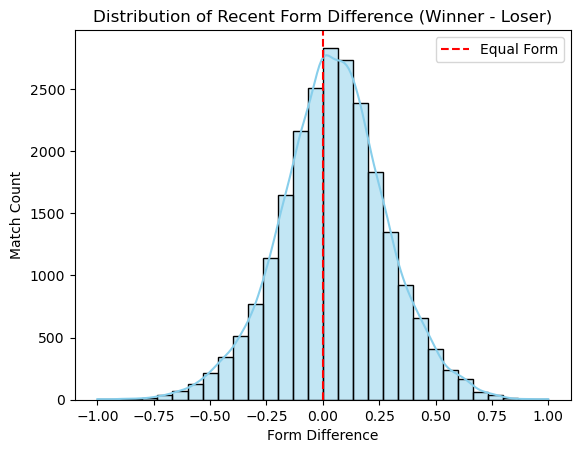

Proportion of matches where winner had higher form: 0.543
Average form difference (winner - loser): 0.046


In [ ]:
from features import compute_recent_form_index

# Apply to dataset
df_3 = compute_recent_form_index(df, surface_specific=False) # Default: window_days=180, max_matches=12
print(df_3[['player1_form','player2_form','form_diff']].describe())

# rename columns cleanly
df_3 = rename_ytd_columns(df_3, "player1_", "player2_")

print(df_3.columns)

df = df.merge(
    df_3[['winner_form','loser_form','form_diff']],
    left_index=True,
    right_index=True,
    how='left'
)

# Compare distributions for winners (player1) and losers (player2)
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['form_diff'].dropna(), bins=30, kde=True, color='skyblue', edgecolor='black')
plt.title('Distribution of Recent Form Difference (Winner - Loser)')
plt.xlabel('Form Difference')
plt.ylabel('Match Count')
plt.axvline(0, color='red', linestyle='--', label='Equal Form')
plt.legend()
plt.show()

# Proportion of matches where winner had higher form
prop_higher_form = (df['form_diff'] > 0).mean()
print(f"Proportion of matches where winner had higher form: {prop_higher_form:.3f}")

#baseline_features_report["Recent Form Index"] = prop_higher_form

# Average difference in form between winners and losers
avg_diff = df['form_diff'].mean()
print(f"Average form difference (winner - loser): {avg_diff:.3f}")

In [ ]:
df = rename_ytd_columns(df, "player1_", "player2_")

print("Print df head:", df.head())

print("Print df columns:", df.columns)

# Much lighter than Excel and rarely times out
df.to_csv("../data/processed/features.csv", index=False)
print("Saved to features.csv")


Print df head:    ATP  Location              Tournament       Date  Series    Court Surface  \
0    1  Brisbane  Brisbane International 2015-01-05  ATP250  Outdoor    Hard   
1    2   Chennai            Chennai Open 2015-01-05  ATP250  Outdoor    Hard   
2    2   Chennai            Chennai Open 2015-01-05  ATP250  Outdoor    Hard   
3    2   Chennai            Chennai Open 2015-01-05  ATP250  Outdoor    Hard   
4    3      Doha  Qatar Exxon Mobil Open 2015-01-05  ATP250  Outdoor    Hard   

       Round  Best of            Winner  ... loser_ytd_Return_Points_Won  \
0  1st Round      3.0         Chardy J.  ...                         33%   
1  1st Round      3.0         Muller G.  ...                         NaN   
2  1st Round      3.0  Haider-Maurer A.  ...                         NaN   
3  1st Round      3.0          Coric B.  ...                         NaN   
4  1st Round      3.0        Bolelli S.  ...                         33%   

   winner_ytd_Total_Points_Won  loser_ytd_Total